# A True/False Decision Tree for Optical Engineering

**The design question:** will this fiber be **single-mode** at my wavelength? *(True / False)*

The physics answer is one inequality. A step-index fiber with core radius $a$ and numerical aperture
NA guides only one mode when

$$V = \frac{2\pi a\,\mathrm{NA}}{\lambda} < 2.405 \qquad(2.405 = \text{first zero of the Bessel function } J_0)$$

This notebook gives the *machine-learning* answer, then shows they're the same thing:

| § | idea |
|---|---|
| 1 | a recursive decision tree learns True/False from examples (raw $a$, NA, $\lambda$) |
| 2 | **feature engineering**: give it $u = a\,\mathrm{NA}/\lambda$ and one split finds the physics |
| 3 | **the tree is algebra**: recursion converts it to a SymPy `Piecewise` and a Boolean formula |
| 4 | recursion vs. loops: counting nodes both ways |
| 5 | 10 yes/no questions = 10 bits = the basis states of **10 qubits** |

Modules: [`dgs/optics_decision_tree.py`](../dgs/optics_decision_tree.py), tree from
[`dgs/decision_tree.py`](../dgs/decision_tree.py) (from scratch, Gini).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.decision_tree import accuracy
from dgs.optics_decision_tree import (
    V_CUTOFF, U_CUTOFF, v_number, single_mode, fiber_dataset, engineered_feature, fit_tree,
    count_nodes_recursive, count_nodes_iterative, depth_recursive, tree_to_piecewise, tree_to_logic,
    leaf_paths, evaluate_piecewise, full_tree_bitstrings, hadamard_uniform_state,
)
X, y = fiber_dataset(2000, seed=0); Xt, yt = fiber_dataset(2000, seed=1)
print(f"{len(y)} training fibers, {100*y.mean():.1f}% single-mode;  SMF-28-like (a=4.1 µm, NA=0.12, 1550 nm): V = {float(v_number(4.1, 0.12, 1.55)):.2f} → single-mode: {bool(single_mode(4.1, 0.12, 1.55))}")

2000 training fibers, 38.3% single-mode;  SMF-28-like (a=4.1 µm, NA=0.12, 1550 nm): V = 1.99 → single-mode: True


# 1. Learning from raw features

Each split asks one true/false question, like "is $\lambda \le 1.1\ \mu$m?". The tree is grown
**recursively**: split, then build the left subtree and the right subtree the same way, until a
node is pure.

,max depth,nodes,test accuracy
0,1,3,0.7855
1,2,7,0.8120
2,3,15,0.8700
3,4,31,0.8895
4,6,91,0.9345
5,8,149,0.9405
6,∞,157,0.9455


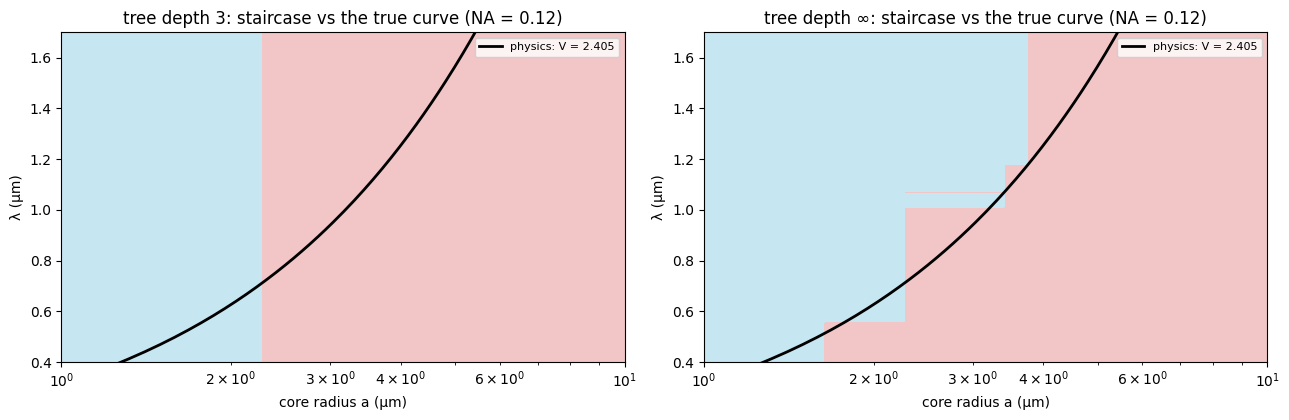

In [2]:
rows = []
for d in (1, 2, 3, 4, 6, 8, None):
    t = fit_tree(X, y, max_depth=d)
    rows.append({"max depth": "∞" if d is None else d, "nodes": count_nodes_recursive(t.root),
                 "test accuracy": accuracy(yt, t.predict(Xt))})
display(pd.DataFrame(rows))
NA0 = 0.12
aa, ll = np.meshgrid(np.exp(np.linspace(0, np.log(10), 300)), np.linspace(0.4, 1.7, 300))
grid = np.column_stack([aa.ravel(), np.full(aa.size, NA0), ll.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, d in zip(axes, (3, None)):
    t = fit_tree(X, y, max_depth=d)
    ax.contourf(aa, ll, t.predict(grid).reshape(aa.shape), levels=[-0.5, 0.5, 1.5], colors=["#f2c6c6", "#c6e6f2"])
    a_line = np.linspace(1, 10, 200); ax.plot(a_line, 2*np.pi*a_line*NA0/V_CUTOFF, "k", lw=2, label="physics: V = 2.405")
    ax.set(xscale="log", ylim=(0.4, 1.7), xlabel="core radius a (µm)", ylabel="λ (µm)",
           title=f"tree depth {'∞' if d is None else d}: staircase vs the true curve (NA = {NA0})")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Blue = predicted single-mode. Every split is horizontal or vertical (one feature at a time), but the
true boundary $\lambda = 2\pi a\,\mathrm{NA}/2.405$ is a slanted curve. So the tree builds a **staircase**:
more depth means more steps, about 150 nodes to reach ~95%.

# 2. Feature engineering: ask the physics question

Give the tree the one combination the physics cares about, $u = a\,\mathrm{NA}/\lambda$:

In [3]:
U, Ut = engineered_feature(X), engineered_feature(Xt)
tu = fit_tree(U, y, max_depth=3)
print(f"nodes: {count_nodes_recursive(tu.root)},  test accuracy: {accuracy(yt, tu.predict(Ut)):.4f}")
print(f"learned threshold u ≤ {tu.root.thresh:.5f}   vs   physics 2.405/2π = {U_CUTOFF:.5f}   ({100*(tu.root.thresh/U_CUTOFF - 1):+.2f}%)")

nodes: 3,  test accuracy: 0.9995
learned threshold u ≤ 0.38325   vs   physics 2.405/2π = 0.38274   (+0.13%)


**One split, 99.95% accuracy**, and the threshold it learned is the Bessel zero divided by $2\pi$, within
0.13%. The learning problem is only as hard as the features make it. Knowing the physics turned a
157-node staircase into a single inequality.

# 3. The tree *is* algebra

Walk the tree recursively. A leaf returns its answer, and a split returns
`Piecewise((left, x ≤ t), (right, True))`. Collecting the conditions along every path that ends in
**True** gives a Boolean formula (an OR of ANDs):

In [4]:
u = sp.Symbol("u", positive=True)
display(Math(r"\text{engineered tree: } f(u) = " + sp.latex(tree_to_piecewise(tu.root, [u]))))
display(Math(r"\text{as logic: } " + sp.latex(tree_to_logic(tu.root, [u]))))
syms = sp.symbols("a NA lambda", positive=True)
t2 = fit_tree(X, y, max_depth=2)
display(Math(r"\text{raw depth-2 tree: } f(a,\mathrm{NA},\lambda) = " + sp.latex(tree_to_piecewise(t2.root, syms))))
display(Math(r"\text{as logic: } " + sp.latex(tree_to_logic(t2.root, syms))))
t4 = fit_tree(X, y, max_depth=4)
print("depth-4 Piecewise reproduces every tree prediction:",
      bool(np.array_equal(evaluate_piecewise(tree_to_piecewise(t4.root, syms), syms, Xt), t4.predict(Xt))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

depth-4 Piecewise reproduces every tree prediction: True


# 4. Recursion vs. loops

Anything recursive can be written with a loop and an explicit stack. Here's counting nodes both ways,
plus each leaf's path as a bit string (left = 0, right = 1):

In [5]:
t5 = fit_tree(X, y, max_depth=5)
print(f"recursive count: {count_nodes_recursive(t5.root)},  loop + stack count: {count_nodes_iterative(t5.root)},  depth: {depth_recursive(t5.root)}")
paths = leaf_paths(t5.root)
print(f"{len(paths)} leaves; in a full binary tree, leaves = (nodes + 1)/2 = {(count_nodes_recursive(t5.root)+1)//2}")
for bits, conds, val in paths[:5]:
    print(f"  {bits:6s} → {'single-mode' if val else 'multimode'}")

recursive count: 55,  loop + stack count: 55,  depth: 5
28 leaves; in a full binary tree, leaves = (nodes + 1)/2 = 28
  00000  → single-mode
  00001  → multimode
  0001   → single-mode
  00100  → multimode
  00101  → single-mode


# 5. Ten yes/no questions = ten bits = ten qubits

A complete tree of depth $n$ asks $n$ binary questions and has $2^n$ leaves, one for every $n$-bit string.
Those are exactly the labels of the **computational basis** of $n$ qubits, $|b_1 b_2\cdots b_n\rangle$. The
difference is that a classical tree follows **one** path, while $n$ Hadamard gates put a qubit register into
an equal superposition of **all** $2^n$ paths at once:

In [6]:
bits = full_tree_bitstrings(10)
psi = hadamard_uniform_state(10)
print(f"depth-10 tree: {len(bits)} leaves, from {bits[0]} to {bits[-1]}")
print(f"H⊗10|0…0⟩: {psi.size} amplitudes, each {psi[0]:.5f} = 2^(-5);  Σ|amp|² = {np.sum(psi**2):.6f}")

depth-10 tree: 1024 leaves, from 0000000000 to 1111111111
H⊗10|0…0⟩: 1024 amplitudes, each 0.03125 = 2^(-5);  Σ|amp|² = 1.000000


That's the honest version of the analogy. A quantum computer doesn't simply "try every leaf". Reading
out the uniform superposition gives one random leaf. Quantum algorithms need interference to make the
*right* answer likely, which is what Grover's search does for exactly this kind of yes/no question.

## Exercises
1. Add a second label, "few-mode" ($2.405 \le V < 3.832$, the first zero of $J_1$), and train a 3-class tree on $u$. How many splits?
2. Give the raw tree $\log a$, $\log \mathrm{NA}$, $\log \lambda$ instead. Why doesn't that fix the staircase? (Hint: the boundary is a *plane* in log space, but splits are still axis-aligned.)
3. Write `tree_to_piecewise` with a loop and an explicit stack instead of recursion.
4. Grover's algorithm finds a marked leaf among $N = 2^n$ in about $\frac{\pi}{4}\sqrt N$ queries. How many for $n = 10$, vs. ~$N/2$ classically?